# Must-know

`int` stays 4-byte even in x64 env.


In [13]:
FORMAT_CHAR = "b"
N_BYTES = 1

t = N_BYTES * 8
t = 1 << t
t //= 2

RNBMIN = -t
RNBMAX = t - 1

MAX_STEP = N_BYTES * 4 * 0x100**1
MAX_PERIOD = RNBMAX - RNBMIN + 1
FILE_NAME = "README.md"

FORMAT_CHAR, N_BYTES, RNBMIN, RNBMAX, MAX_STEP, FILE_NAME

('b', 1, -128, 127, 1024, 'README.md')

In [14]:
f = open(FILE_NAME, "rb")
srcb = f.read(MAX_STEP)
f.close()
len(srcb)

1024

In [15]:
import numpy as np, struct

srcb = list(struct.unpack("<" + FORMAT_CHAR * (len(srcb) // N_BYTES), srcb))
arr = np.array(srcb)

In [16]:
arr.shape

(1024,)

In [17]:
bin(arr.shape[0])

'0b10000000000'

In [18]:
np.min(arr), np.max(arr)

(np.int64(-128), np.int64(124))

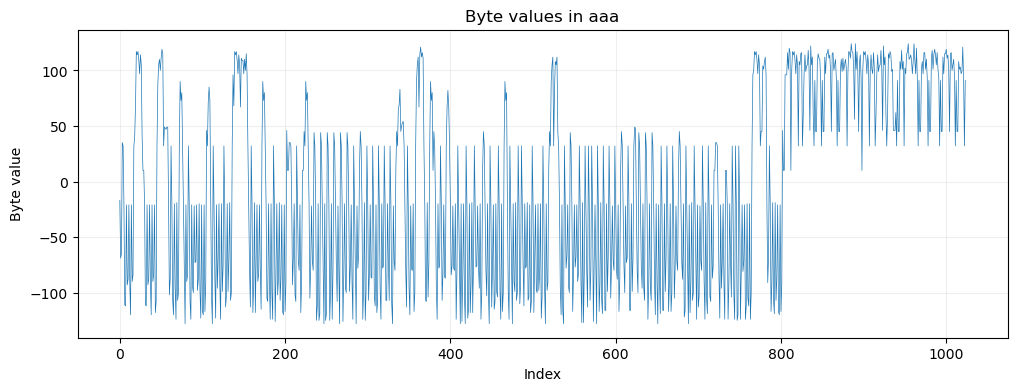

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(arr[:MAX_STEP], color="tab:blue", linewidth=0.5)
plt.title("Byte values in aaa")
plt.xlabel("Index")
plt.ylabel("Byte value")
plt.grid(alpha=0.2)
plt.show()

In [20]:
arr[:0x10]

array([ -17,  -69,  -65,   35,   32,  -21, -111, -112,  -21,  -93,  -88,
        -21,  -89, -120,  -21,  -90])

In [21]:
arr[-0x10:]

array([105, 110,  93,  32,  91,  45,  45, 108, 101, 103,  97,  99, 121,
        93,  32,  91])

In [22]:
import pandas as pd

idxlim = min(arr.shape[0], MAX_PERIOD)
psm = pd.Series([np.mean(arr[::step]) for step in range(1, idxlim)], range(1, idxlim))
psm

1      -7.621094
2      -8.507812
3      -7.228070
4      -6.078125
5      -7.039024
         ...    
251    -4.200000
252     0.200000
253     2.800000
254   -28.800000
255   -17.200000
Length: 255, dtype: float64

In [23]:
psm.sort_values(ascending=False, key=(lambda x: np.abs(x)))

242   -64.800000
185   -55.000000
217   -54.000000
249   -52.600000
219   -50.200000
         ...    
172    -0.166667
45     -0.130435
29     -0.083333
162     0.000000
148     0.000000
Length: 255, dtype: float64

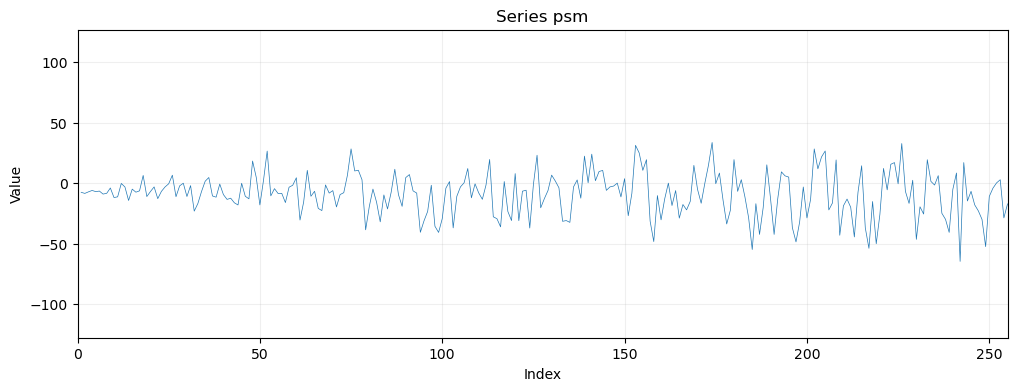

In [24]:
plt.figure(figsize=(12, 4))
plt.xlim((0, min(len(psm), MAX_PERIOD)))
plt.ylim((-128, 127))
plt.plot(psm, color="tab:blue", linewidth=0.5)
plt.title("Series psm")
plt.xlabel("Index")
plt.ylabel("Value")
plt.grid(alpha=0.2)
plt.show()